In [4]:
from langgraph.graph import StateGraph , START,END
from langchain_core.messages import BaseMessage , HumanMessage
from langgraph.graph.message import BaseMessage, add_messages
from typing import TypedDict, Annotated
from langchain_mistralai import ChatMistralAI

In [3]:
class ChatState(TypedDict):

   messages: Annotated[list[BaseMessage], add_messages]

In [5]:

llm = ChatMistralAI(model="ministral-3b-latest", temperature=0.7)


In [6]:
def chatnode(state: ChatState):
    messages = state['messages']
    response = llm.invoke(messages)
    return {'messages': [response]}

In [7]:
graph  = StateGraph(ChatState)

graph.add_node('chatnode' , chatnode)

graph.add_edge(START , 'chatnode')
graph.add_edge('chatnode' , END)

chatbot = graph.compile()

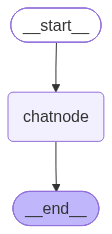

In [8]:
chatbot